# Guía L1 — La factura de la ciudad · **Sesión 1: la ciudad en una tabla**

**Cálculo Diferencial — Laboratorio computacional** · Universidad Nacional de Colombia, Sede Manizales

> Esta idea no salió de un libro. Salió de una ducha en Londres. La historia completa está en la guía impresa — léanla antes de tocar este cuaderno, porque este cuaderno es la mitad ejecutable de esa historia.

**Cómo usar este cuaderno en Colab:** primero guarden su propia copia (`Archivo → Guardar una copia en Drive`) y renómbrenla `L1_apellidos.ipynb`. Trabajen sobre la copia. Las celdas marcadas con ✏️ son de ustedes: hay que completarlas. Las celdas de texto marcadas con 🗣️ son para escribir conclusiones del equipo, con sus palabras.

---
## ⏸️ Antes de ejecutar nada: Momento 1 — Predecir

Está en la guía (P1, P2, P3). **En papel, a mano, 15 minutos.** Cuando terminen, tómenle foto: va en el informe. Si ya lo hicieron, sigan. Si no, este cuaderno puede esperar; la predicción no.

---
## 1 · Tres palabras nuevas antes del primer `import`

**CSV** (*comma-separated values*): el formato más humilde y universal para tablas. Un archivo de texto plano: cada línea es una fila, las columnas van separadas por comas. Sin colores, sin fórmulas. Es el idioma en que las instituciones del mundo publican lo que miden.

**API**: para lo que nos importa hoy, un mesero de datos. Una URL bien construida es un pedido; el servidor responde con la tabla. Hoy el archivo de Londres lo servimos congelado desde el repositorio del curso (así todos trabajamos con exactamente los mismos datos); en la sesión 2 sí pediremos las tarifas de la CHEC en vivo, por API, al Estado colombiano.

**Dataset**: una tabla con pretensiones — datos **más su documentación**: qué mide cada columna, en qué unidades, quién los recogió, cuándo. Una tabla sin unidades es un chisme sin fuente.

Nuestro dataset de hoy: consumos eléctricos **reales** de miles de hogares de Londres, medidos por contadores inteligentes entre 2011 y 2014 (proyecto *Low Carbon London*, UK Power Networks), agregados por nosotros a consumo **mensual** por hogar. Columnas: `hogar` (código anónimo), `mes` (año-mes), `kwh` (consumo del mes en kilovatios-hora).

In [1]:
# Herramientas del día: pandas (tablas) y matplotlib (gráficas).
import pandas as pd
import matplotlib.pyplot as plt

# El CSV congelado del curso. Esta URL la da el profesor / monitor.
RUTA = "https://raw.githubusercontent.com/cmorregof/labs-calculo-2026-2/main/datos/londres_mensual.csv"   # el CSV congelado, servido desde el repositorio del curso

df = pd.read_csv(RUTA)
print("Datos cargados. Eso que acaba de pasar: un archivo de texto se volvió una tabla en memoria.")

Datos cargados. Eso que acaba de pasar: un archivo de texto se volvió una tabla en memoria.


---
## 2 · Conocer el dataset (mirar antes de cruzar)

Antes de calcular **cualquier** cosa, respondemos con código cuatro preguntas: ¿cuántas filas? ¿cuántas columnas? ¿cuántos hogares distintos? ¿qué rango de meses? A esto se le llama *conocer el dataset* y hacerlo primero es el equivalente a mirar antes de cruzar la calle.

In [13]:
print("Filas y columnas:", df.shape)
df.head(27)   # las primeras 10 filas, para ver la cara de los datos

Filas y columnas: (113440, 3)


,hogar,mes,kwh
0,MAC000002,2012-11,345.02
1,MAC000002,2012-12,355.76
2,MAC000002,2013-01,360.08
3,MAC000002,2013-02,381.84
4,MAC000002,2013-03,480.17
5,MAC000002,2013-04,362.74
6,MAC000002,2013-05,304.06
7,MAC000002,2013-06,300.12
8,MAC000002,2013-07,271.32
9,MAC000002,2013-08,270.05


In [4]:
# ✏️ Ejercicio 1 — Completen las dos líneas que faltan.
print("Hogares distintos:", df["hogar"].nunique())
print("Primer mes:", df["mes"].min())
print("Primer mes:", df["mes"].max())
print("Meses distintos:", df["mes"].nunique())
# print("Último mes:", ...)                      # ← su turno
# print("¿Cuántos meses distintos hay?:", ...)   # ← su turno

Hogares distintos: 5556
Primer mes: 2011-12
Primer mes: 2014-02
Meses distintos: 27


---
## 3 · El dominio de cada columna (los avisos en el piso)

En Londres, el piso te grita **LOOK LEFT** porque el peligro viene del lado que no esperas. **En un dataset nadie pinta avisos en el piso: los pintan ustedes.** Escribir el dominio de cada columna es decidir, *antes* de operar, qué valores son legales y desde dónde pueden venir los ilegales.

🗣️ **Completen esta tabla en esta misma celda (doble clic para editar):**

| Columna | Dominio matemático (notación de conjuntos) | ¿Discreto o continuo? | Valores ilegales posibles |
|---|---|---|---|
| `hogar` | H = {códigos de la forma "MAC" + 6 dígitos} conjunto finito (5.556 elementos) | Discreto, nominal | Códigos vacíos, de longitud distinta de 9, o el mismo hogar escrito con grafías distintas |
| `mes` | M = {2011-12, 2012-01, …, 2014-02}, 27 elementos | Discreto, ordenado y cíclico | Fechas fuera del estudio, formato distinto a AAAA-MM, vacíos, el mismo mes repetido para un hogar |
| `kwh` | [0, M] ⊂ ℝ, con M un máximo razonable |Continuo | Negativos, vacíos (NaN), valores absurdos |


In [14]:
# La policía de dominios: comparamos los datos contra el dominio que declararon.
print("--- Resumen estadístico de kwh ---")
print(df["kwh"].describe())
print()
print("Valores faltantes (NaN) por columna:")
print(df.isna().sum())
print()
print("¿Consumos negativos?:", (df["kwh"] < 0).sum())
print("¿Filas duplicadas (mismo hogar, mismo mes)?:", df.duplicated(subset=["hogar", "mes"]).sum())

--- Resumen estadístico de kwh ---
count    113440.000000
mean        307.941202
std         254.083962
min           0.000000
25%         153.960000
50%         244.800000
75%         380.542500
max        6391.360000
Name: kwh, dtype: float64

Valores faltantes (NaN) por columna:
hogar    0
mes      0
kwh      0
dtype: int64

¿Consumos negativos?: 0
¿Filas duplicadas (mismo hogar, mismo mes)?: 0


In [ ]:
# ✏️ Ejercicio 2 — Juzgar y decidir.
# Si la policía de dominios encontró infractores (NaN, negativos, duplicados, valores absurdos),
# decidan QUÉ HACER con cada tipo (eliminar, corregir, conservar con nota) y háganlo aquí.
# Regla de oro: toda decisión queda escrita en un comentario. Un dato eliminado sin explicación
# es un dato escondido.
# df = df[ ... ]   # ← su decisión, si aplica
print("Filas después de la limpieza:", len(df))
# Decicion: No se elimina niguna fila, ya que no se encontraron infractores, no hay valores vacios tampoco negativos, no hay meses ni hogares duplicados

Filas después de la limpieza: 113440


---
## 4 · Primeras vistas: ¿dónde está el hogar típico?

Un histograma reparte los consumos mensuales en cajones y cuenta cuántos caen en cada uno. Es la primera radiografía de la ciudad. **Antes de correr la celda:** revisen su P1 — ¿cuántos kWh al mes predijeron para el hogar londinense típico?

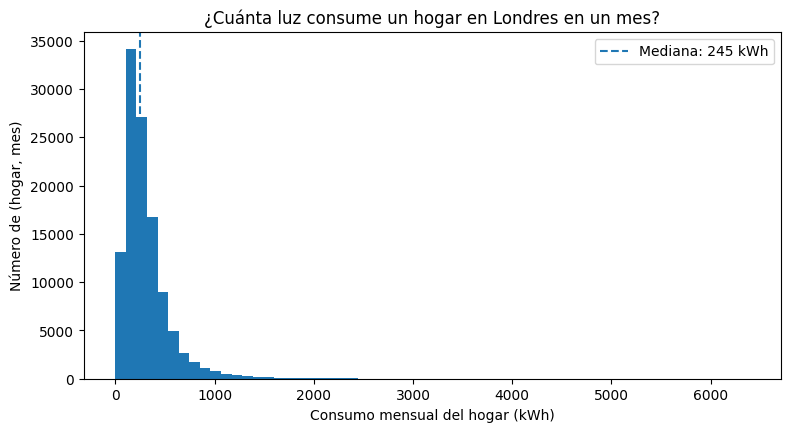

La mitad de los registros está por debajo de 245 kWh/mes.


In [15]:
plt.figure(figsize=(9, 4.5))
plt.hist(df["kwh"], bins=60)
plt.xlabel("Consumo mensual del hogar (kWh)")
plt.ylabel("Número de (hogar, mes)")
plt.title("¿Cuánta luz consume un hogar en Londres en un mes?")
plt.axvline(df["kwh"].median(), linestyle="--", label=f"Mediana: {df['kwh'].median():.0f} kWh")
plt.legend()
plt.show()

print("La mitad de los registros está por debajo de", round(df["kwh"].median()), "kWh/mes.")

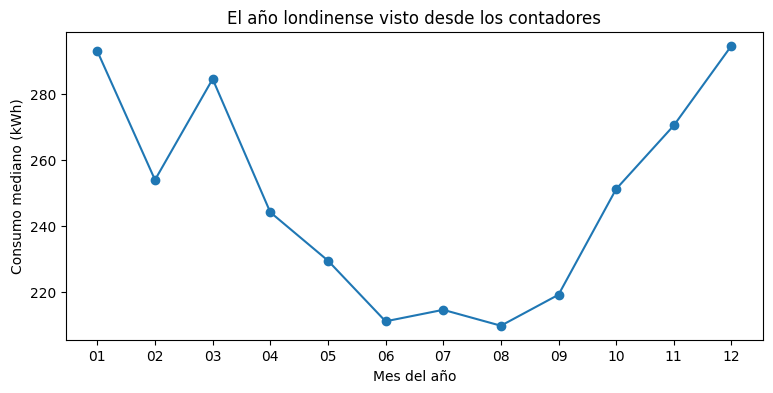

In [16]:
# ✏️ Ejercicio 3 — El invierno en una curva.
# Construyan la curva del consumo MEDIANO por mes calendario (ene, feb, ..., dic).
# Pista: extraigan el número de mes con  df["mes"].str[5:7]  y usen groupby + median.

df["mes_num"] = df["mes"].str[5:7]
mediana_mensual = df.groupby("mes_num")["kwh"].median()

plt.figure(figsize=(9, 4))
plt.plot(mediana_mensual.index, mediana_mensual.values, marker="o")
plt.xlabel("Mes del año")
plt.ylabel("Consumo mediano (kWh)")
plt.title("El año londinense visto desde los contadores")
plt.show()

# 🗣️ ¿Apareció el invierno donde lo predijeron en P2? ¿En qué meses? ¿Por qué el pico
#    está donde está? (Piensen en la calefacción... y en qué hemisferio queda Londres.)

### Respuesta
En P2 predijimos que lo meses mas caro se encontraban en el invierno en los meses de diciembre a febrero, en la grafica se aprecia que los meses mas caros son en diciembre y en enero, aunque en febrero hubo una baja. Estos picos en la grafica se debe al frio invierno donde los hogares hace un uso masivo de la energia, usando constantemente la calefaccion en sus hogares, ademas del uso cotidiano de la energia. Tambien recordemos que londres se encuentra en el esmiferio norte lo cual hace que tenga cambios estaciones climaticos, por tal motivo en algunos meses tiene picos mas altos o bajos de energia 

---
## 5 · La pregunta importante: ¿el consumo es una *función* del mes?

Vamos a graficar **la nube completa**: un punto por cada pareja (mes, consumo de un hogar). Antes de correr la celda, relean su respuesta a P3.

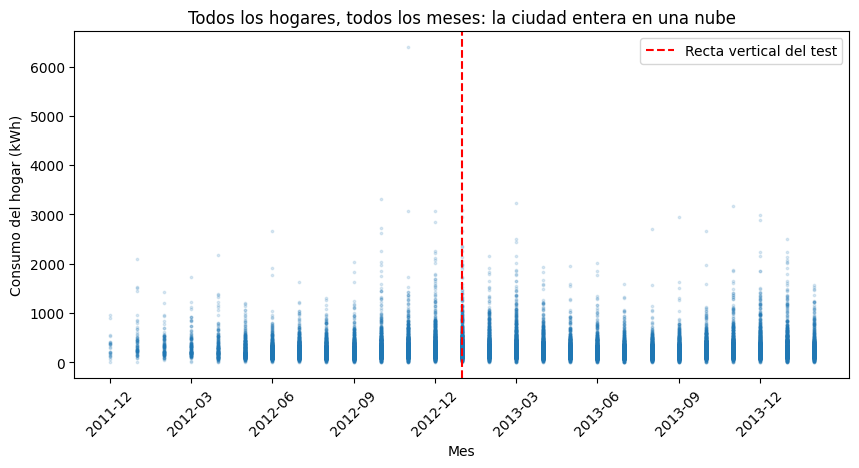

¿Cuántos consumos distintos tiene el mes 2013-01?: 5258


In [17]:
# La nube completa (si hay muchos puntos, muestreamos 20.000 para que la gráfica respire).
muestra = df.sample(min(20000, len(df)), random_state=1)

meses = sorted(df["mes"].unique())
pos = {m: i for i, m in enumerate(meses)}   # posición de cada mes en el eje x

plt.figure(figsize=(10, 4.5))
plt.scatter(muestra["mes"].map(pos), muestra["kwh"], s=3, alpha=0.15)
plt.xticks(range(0, len(meses), 3), meses[::3], rotation=45)
plt.xlabel("Mes")
plt.ylabel("Consumo del hogar (kWh)")
plt.title("Todos los hogares, todos los meses: la ciudad entera en una nube")

# La recta vertical del test, dibujada sobre un mes cualquiera:
plt.axvline(pos[meses[len(meses)//2]], color="red", linewidth=1.5, linestyle="--",
            label="Recta vertical del test")
plt.legend()
plt.show()

un_mes = meses[len(meses)//2]
print(f"¿Cuántos consumos distintos tiene el mes {un_mes}?:",
      df[df['mes'] == un_mes]['kwh'].nunique())

🗣️ **La recta roja atraviesa la nube ¿en cuántos puntos?** Entonces: sobre toda la ciudad, ¿el consumo es función del mes? Escriban aquí su veredicto **usando la definición formal de la clase** (dominio, codominio, regla):

*(doble clic y escriban aquí)*

Ahora viene el movimiento clave. Vamos a **condicionar**: en lugar de toda la ciudad, un solo hogar.

In [ ]:
# ✏️ Ejercicio 4 — Un solo hogar.
# Elijan un código de hogar (mírenlos con df["hogar"].unique()[:10]) y grafiquen SU serie:
# mes en el eje x, kwh en el eje y. ¿Cuántos puntos atraviesa ahora una recta vertical?

hogar_elegido = df["hogar"].unique()[0]   # ← cambien por el hogar que quieran
serie = df[df["hogar"] == hogar_elegido].sort_values("mes")

plt.figure(figsize=(10, 4))
plt.plot(serie["mes"].map(pos), serie["kwh"], marker="o", markersize=4)
plt.xticks(range(0, len(meses), 3), meses[::3], rotation=45)
plt.xlabel("Mes")
plt.ylabel("Consumo (kWh)")
plt.title(f"La historia eléctrica del hogar {hogar_elegido}")
plt.show()

print("Registros de este hogar:", len(serie),
      "| ¿Algún mes repetido?:", serie["mes"].duplicated().sum())

🗣️ **Conclusión del movimiento (la frase más importante del laboratorio):**

Al condicionar por hogar, la relación **se volvió** función, porque: *(explíquenlo con dominio, codominio y regla)*

Frase obligatoria del informe — complétenla con sus palabras: **“Una relación deja de ser función cuando…”**

---
## 6 · Momento 3 — Explicar

🗣️ Media página del equipo, aquí mismo: ¿qué predijeron (P1, P2, P3)? ¿Qué encontraron? ¿Cuál fue la discrepancia más interesante y a qué la atribuyen?

---
## 🤖 Protocolo de IA (recordatorio)

La IA es tutora y auditora, no autora. Intento propio antes de consultar; la IA no es la autoridad final; **todo uso va a la bitácora individual** (prompt → fragmento de respuesta → qué aceptaron / corrigieron / rechazaron). Para depurar: *"Este código da este error: [ambos]. No me des el código corregido; explícame el error y hazme una pregunta que me guíe."* Todo integrante debe poder explicar cualquier celda si el monitor la señala.

**Próxima sesión:** las tarifas de la CHEC llegan por API, ustedes deciden qué estrato le toca a cada hogar londinense, y la nube se llena de pesos colombianos. Traigan **el recibo de energía de su casa**.